# CsI–SiPM：脉冲强度能否解释剩余波动差异？

2026-11-02。在英文提交`75641c2a0f52056fd1bc4ae25271f063480715da`（`Diagnose time-resolved CsI SiPM fluctuation differences`）push并核对远端后继续。[上一轮时间分段诊断](codex_0001_csi_time_resolved_fluctuations.ipynb)发现Am241最大的带符号方差差额落在t10后500–1000 ns。本轮检验这种差额是否主要来自脉冲平均信号强度的简单线性变化。

**结论：简单线性强度关系没有解释Am241的差额。** 用首段平均强度扣除线性关系后，整体F202的MC/实测SD比仍为1.171/1.186，对折残差比为1.138/1.162。首段固定分母项本身也仍偏宽。这里计算的是诊断残差，尚未修改任何模拟参数或ADC，也没有改善正式PID。

只使用既有实测与原生C++/Geant4波形的已核验时间分段数组、原Q箱和原512组重采样。没有新实验、新母事件或新增读出。Am241包括α与γ/电子，不能用源标签代替实验逐事件粒子真值。


|源|读出|强度预测量|原F202比|同样本残差比|有效组分位范围|对折残差比|有效组分位范围|
|---|---|---|---|---|---|---|---|
|Co60|split_r0|mean_500_1000|1.045|1.056|[1.007, 1.147] (512/512)|0.9648|[0.8221, 1.023] (399/512)|
|Co60|split_r0|whole_mean|1.045|1.051|[1.001, 1.144] (512/512)|0.9554|[0.8245, 1.05] (399/512)|
|Co60|split_r1|mean_500_1000|1.041|1.052|[0.9991, 1.14] (512/512)|0.9587|[0.8098, 1.023] (399/512)|
|Co60|split_r1|whole_mean|1.041|1.046|[0.9948, 1.129] (512/512)|0.9506|[0.8166, 1.052] (399/512)|
|Am241|split_r0|mean_500_1000|1.162|1.171|[1.095, 1.281] (512/512)|1.138|[1.016, 1.24] (509/512)|
|Am241|split_r0|whole_mean|1.162|1.175|[1.099, 1.287] (512/512)|1.156|[1.037, 1.266] (509/512)|
|Am241|split_r1|mean_500_1000|1.176|1.186|[1.114, 1.304] (512/512)|1.162|[1.032, 1.276] (509/512)|
|Am241|split_r1|whole_mean|1.176|1.194|[1.121, 1.312] (512/512)|1.175|[1.058, 1.287] (509/512)|

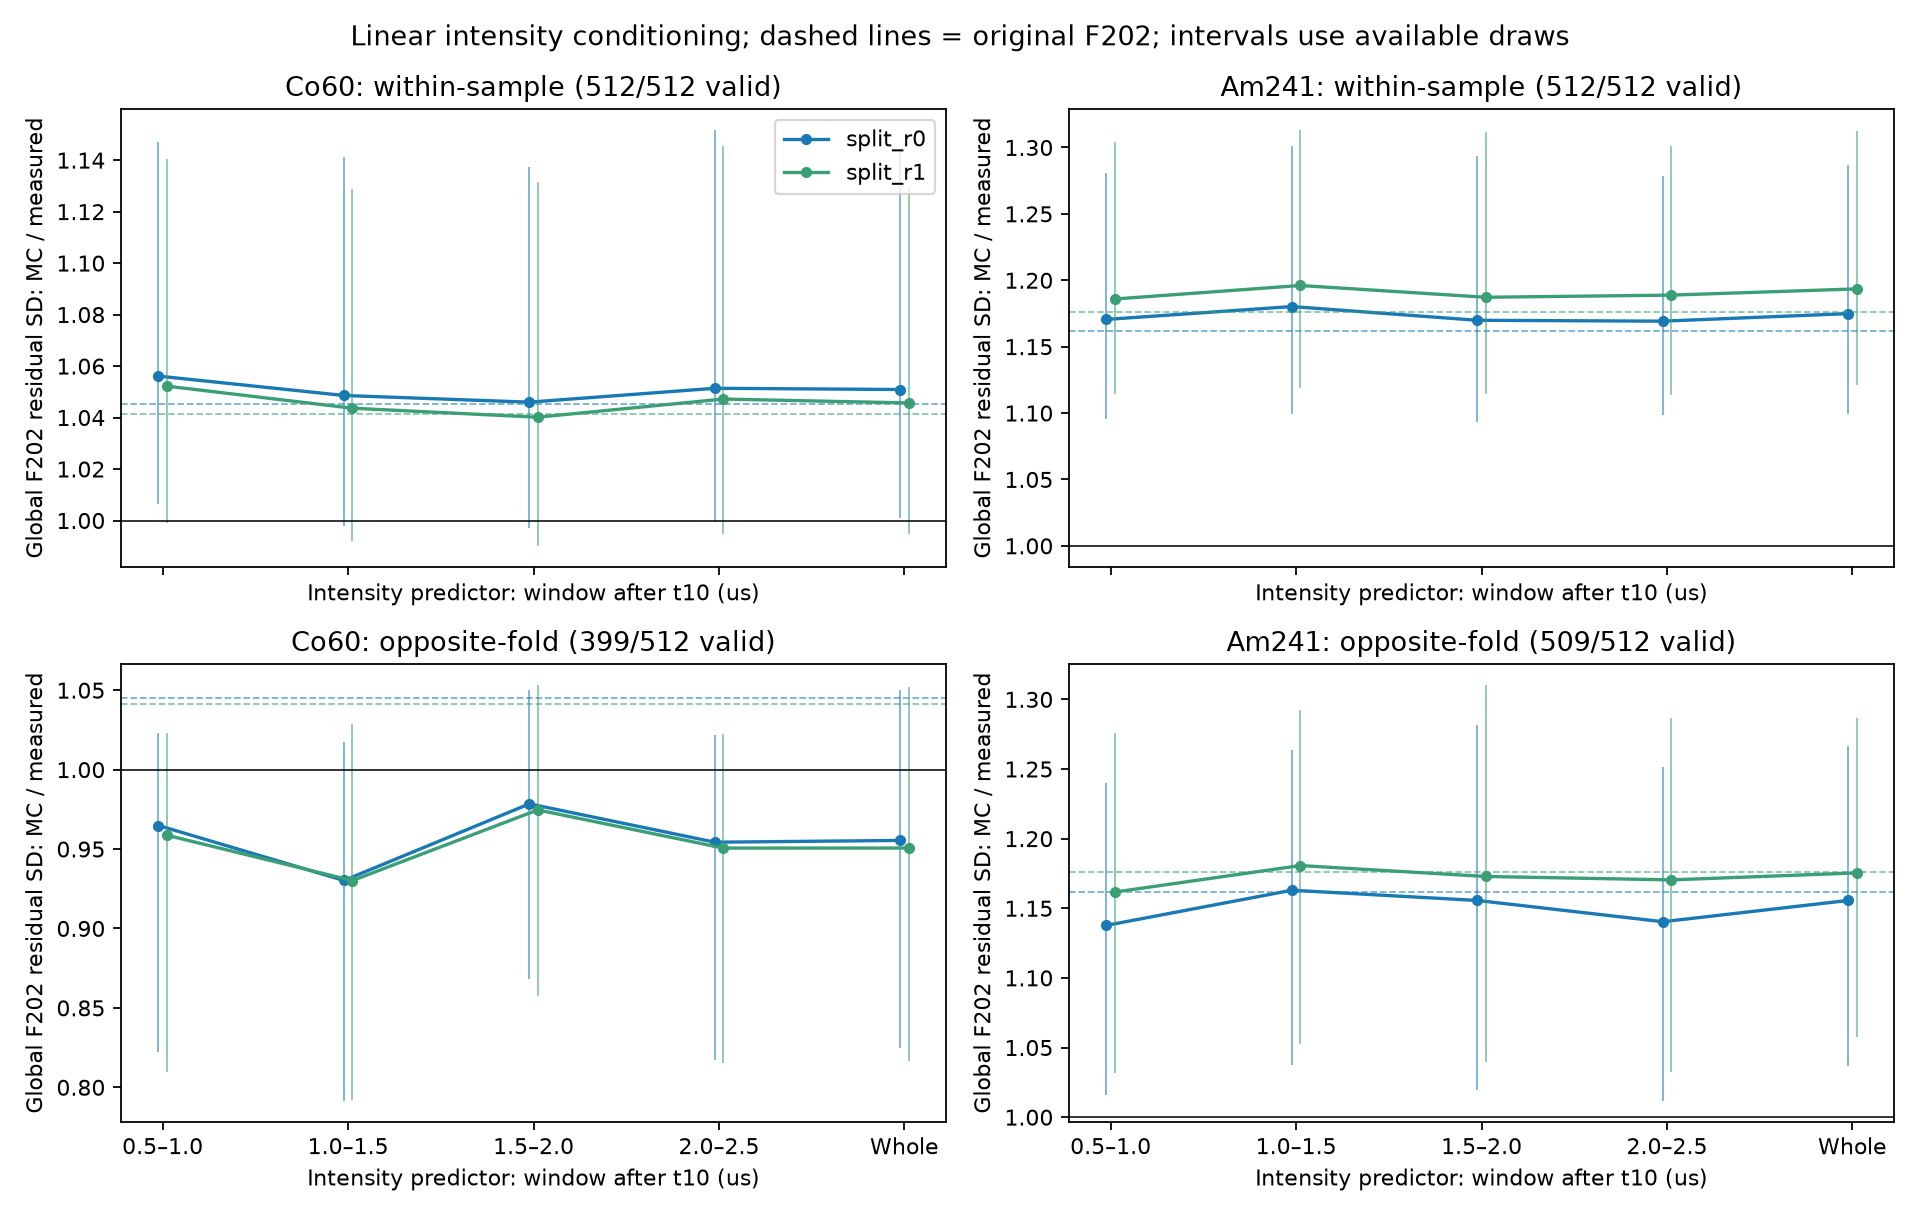

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display, Markdown, Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/intensity_condition_20261102'
def read(path): return json.loads(Path(path).read_text())
def fmt(x): return '不可估计' if x is None else f'{x:.4g}'
def ci(x): return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(y) for y in x['CI95'])+f"] ({x['valid_draws']}/512)"
def table(head,rows): return '\n'.join(['|'+'|'.join(head)+'|','|'+'|'.join(['---']*len(head))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
p=read(OUT/'protocol.json');a=read(OUT/'analysis.json');d=read(OUT/'decision.json')
rows=[]
for source,g in a.items():
    for v,r in g['variants'].items():
        for predictor in [p['predictors'][0],p['predictors'][-1]]:
            z=r['global'][predictor]['202'];q=z['point']
            rows.append([source,v,predictor,fmt(q['original_SD_ratio']),fmt(q['residual_SD_ratio']),ci(z['CI95']['residual_SD_ratio']),fmt(q['crossfit_residual_SD_ratio']),ci(z['CI95']['crossfit_residual_SD_ratio'])])
display(Markdown(table(['源','读出','强度预测量','原F202比','同样本残差比','有效组分位范围','对折残差比','有效组分位范围'],rows)))
display(Image(filename=str(OUT/'figures/intensity_global_residuals.png')))

## 1. 固定设计：同一Q箱内的五种一维关系

保持Co60 run 3、Am241 run 12的last20、B128、原质量条件、当前Q及支持箱。沿用已核验的四段250样点窗口（每段500 ns），以及整段1000样点窗口。对每个窗口均值$\mu_k$和整体均值$\mu$，分别构造$x=\mu_k/\mu_0$或$x=\mu/\mu_0$。$\mu_0$仍是先前对折、每Q箱的参考；不重新拟合幅度标尺。

五种$x$是**五个分别进行的一维回归**，不是五变量联合拟合。每种关系都保留三个滤波尺度和两个源。每个Q箱保留原上下半箱的目标质量；MC与实测分别做描述性拟合，再按Q箱等权汇总协方差。没有按强度删除或重新加权事件。

回归响应是上一轮七项$\mathbf T$，其和逐事件等于原整体$F$。以每箱加权总体矩记

\[
v_x=\operatorname{Var}(x),\quad \mathbf c=\operatorname{Cov}(\mathbf T,x),\quad
\boldsymbol\beta=\frac{\mathbf c}{v_x},\quad
C_{\rm linear}=\frac{\mathbf c\mathbf c^\top}{v_x},\quad
C_{\rm residual}=C-C_{\rm linear}.
\]

这是带截距加权最小二乘的精确同样本方差分解。先在各Q箱计算，再等权平均，之后对矩阵元素求和得到整体F的方差；不是先把不同Q箱混合后拟合。差额均以实测原整体F方差归一化，线性差额与剩余差额之和严格等于原差额。单个样本的线性方差非负，但MC减实测的线性差额可以为负。

**预测量和响应都来自同一带噪ADC。** 该关系可能包含内生相关、曲率、归一化、源混合等，不能用回归系数直接解释SiPM物理噪声，也不能据此给实验波形做校正。


|源|读出|尺度/ns|原方差差额|线性差额|剩余差额|实测线性方差占比|MC线性方差占比|
|---|---|---|---|---|---|---|---|
|Co60|split_r0|50|0.1509|-0.006174|0.1571|0.006965|0.0006873|
|Co60|split_r0|102|-0.01202|-0.006269|-0.005749|0.008448|0.002206|
|Co60|split_r0|202|0.09287|-0.01977|0.1126|0.02366|0.003564|
|Co60|split_r1|50|-0.1163|-0.004195|-0.1121|0.006965|0.003134|
|Co60|split_r1|102|-0.09585|-0.00623|-0.08962|0.008448|0.002454|
|Co60|split_r1|202|0.08427|-0.02034|0.1046|0.02366|0.003066|
|Am241|split_r0|50|-0.07634|0.002432|-0.07877|0.001884|0.004673|
|Am241|split_r0|102|0.05462|-0.006486|0.0611|0.01271|0.005904|
|Am241|split_r0|202|0.35|-0.01339|0.3634|0.01811|0.003491|
|Am241|split_r1|50|-0.06948|0.004405|-0.07388|0.001884|0.006759|
|Am241|split_r1|102|0.1427|-0.01142|0.1541|0.01271|0.001131|
|Am241|split_r1|202|0.3837|-0.01529|0.399|0.01811|0.002036|

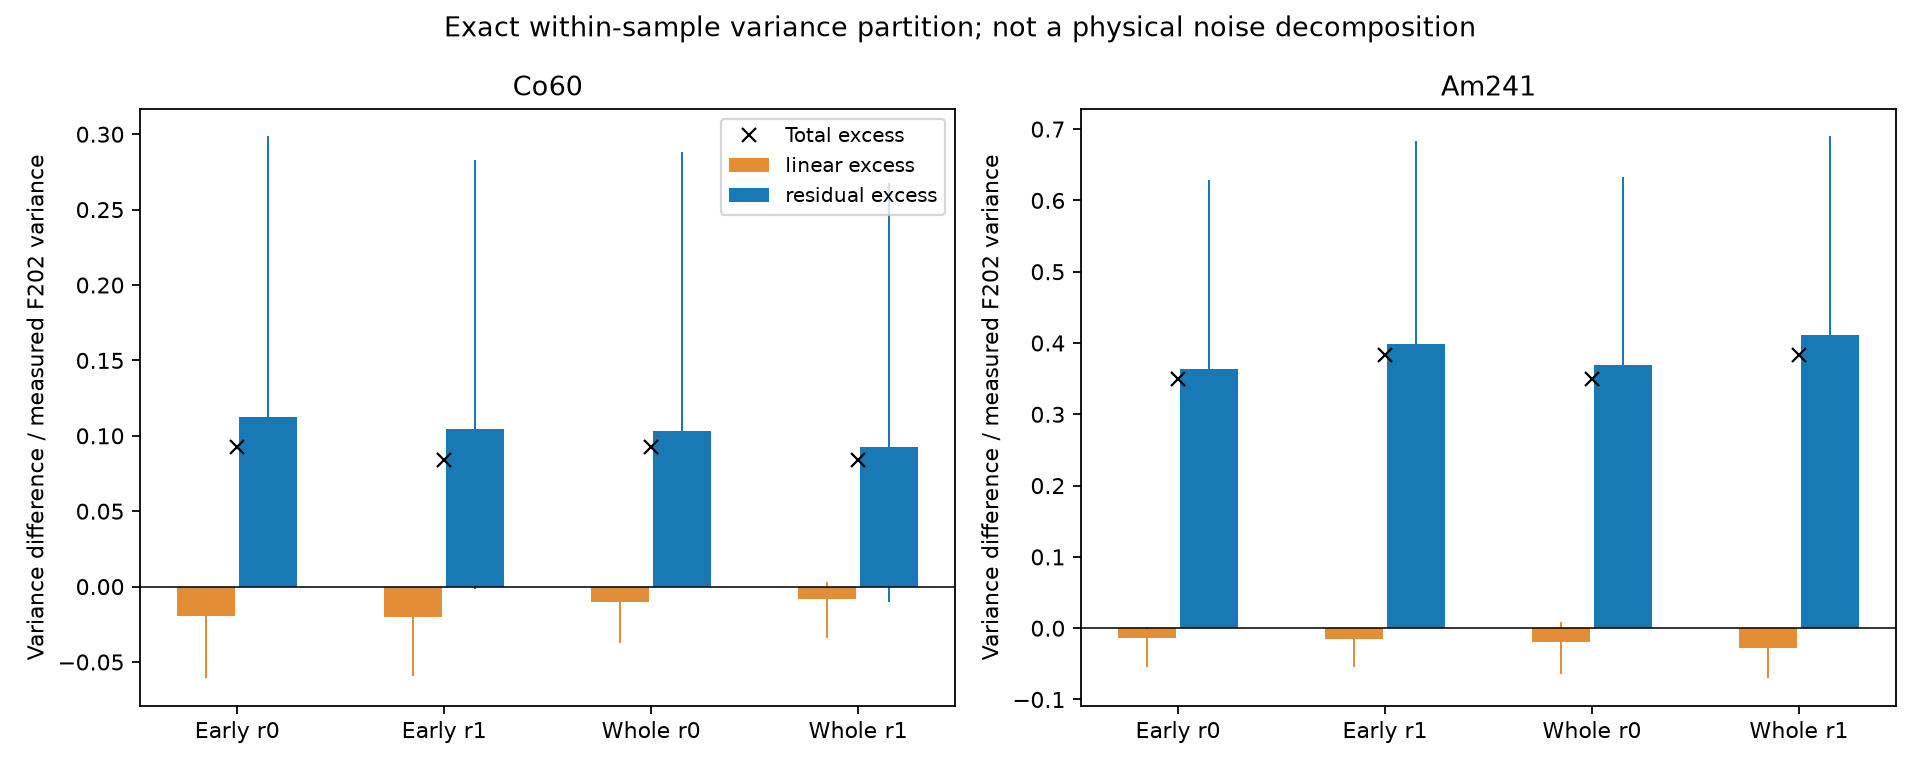

In [2]:
rows=[]
for source,g in a.items():
    for v,r in g['variants'].items():
        for scale in ['50','102','202']:
            z=r['global'][p['predictors'][0]][scale];q=z['point']
            rows.append([source,v,scale,fmt(q['variance_excess']),fmt(q['linear_excess']),fmt(q['residual_excess']),fmt(q['data_linear_fraction']),fmt(q['MC_linear_fraction'])])
display(Markdown(table(['源','读出','尺度/ns','原方差差额','线性差额','剩余差额','实测线性方差占比','MC线性方差占比'],rows)))
display(Image(filename=str(OUT/'figures/intensity_variance_partition.png')))

## 2. 首段和其他时间窗口的剩余离散

局部检查使用$T_k=(249/999)V_k/\mu_0$，并以本窗口的$\mu_k/\mu_0$为预测量。这里比较的是**七项分解中的固定分母窗口项**，没有减去前触发方差，也没有除以随机局部均值，所以不能与上一轮局部$F_k=(V_k-V_{\rm pre})/\mu_k$的SD比混用。

Am241首段窗口项原SD比为1.119/1.163，扣除同样本线性关系后为1.142/1.183，对折残差为1.124/1.173。这个结果支持继续研究相近强度下的剩余离散及时间相关结构；它没有排除全部非线性强度模型，更没有唯一确定微观机制。


|源|读出|窗口/ns|原窗口项SD比|同样本残差比|对折残差比|有效组分位范围|
|---|---|---|---|---|---|---|
|Co60|split_r0|500–1000|0.9991|1.021|0.9353|[0.799, 1.029] (399/512)|
|Co60|split_r0|1000–1500|1.028|1.036|0.9983|[0.8736, 1.13] (399/512)|
|Co60|split_r0|1500–2000|0.944|0.9725|0.9333|[0.8144, 1.027] (399/512)|
|Co60|split_r0|2000–2500|0.8748|0.8915|0.7632|[0.6579, 0.8753] (399/512)|
|Co60|split_r1|500–1000|0.9956|1.018|0.935|[0.7993, 1.028] (399/512)|
|Co60|split_r1|1000–1500|1.009|1.019|0.9841|[0.8549, 1.11] (399/512)|
|Co60|split_r1|1500–2000|0.9741|1.004|0.9659|[0.8525, 1.054] (399/512)|
|Co60|split_r1|2000–2500|0.8355|0.8536|0.733|[0.6312, 0.8446] (399/512)|
|Am241|split_r0|500–1000|1.119|1.142|1.124|[1.001, 1.206] (509/512)|
|Am241|split_r0|1000–1500|1.056|1.11|1.088|[0.9772, 1.18] (509/512)|
|Am241|split_r0|1500–2000|0.8521|0.8881|0.8595|[0.7515, 0.9769] (509/512)|
|Am241|split_r0|2000–2500|1.138|1.174|1.16|[0.9499, 1.347] (509/512)|
|Am241|split_r1|500–1000|1.163|1.183|1.173|[1.039, 1.274] (509/512)|
|Am241|split_r1|1000–1500|1.06|1.109|1.077|[0.9719, 1.164] (509/512)|
|Am241|split_r1|1500–2000|0.909|0.9493|0.9208|[0.8045, 1.048] (509/512)|
|Am241|split_r1|2000–2500|1.062|1.096|1.078|[0.8805, 1.275] (509/512)|

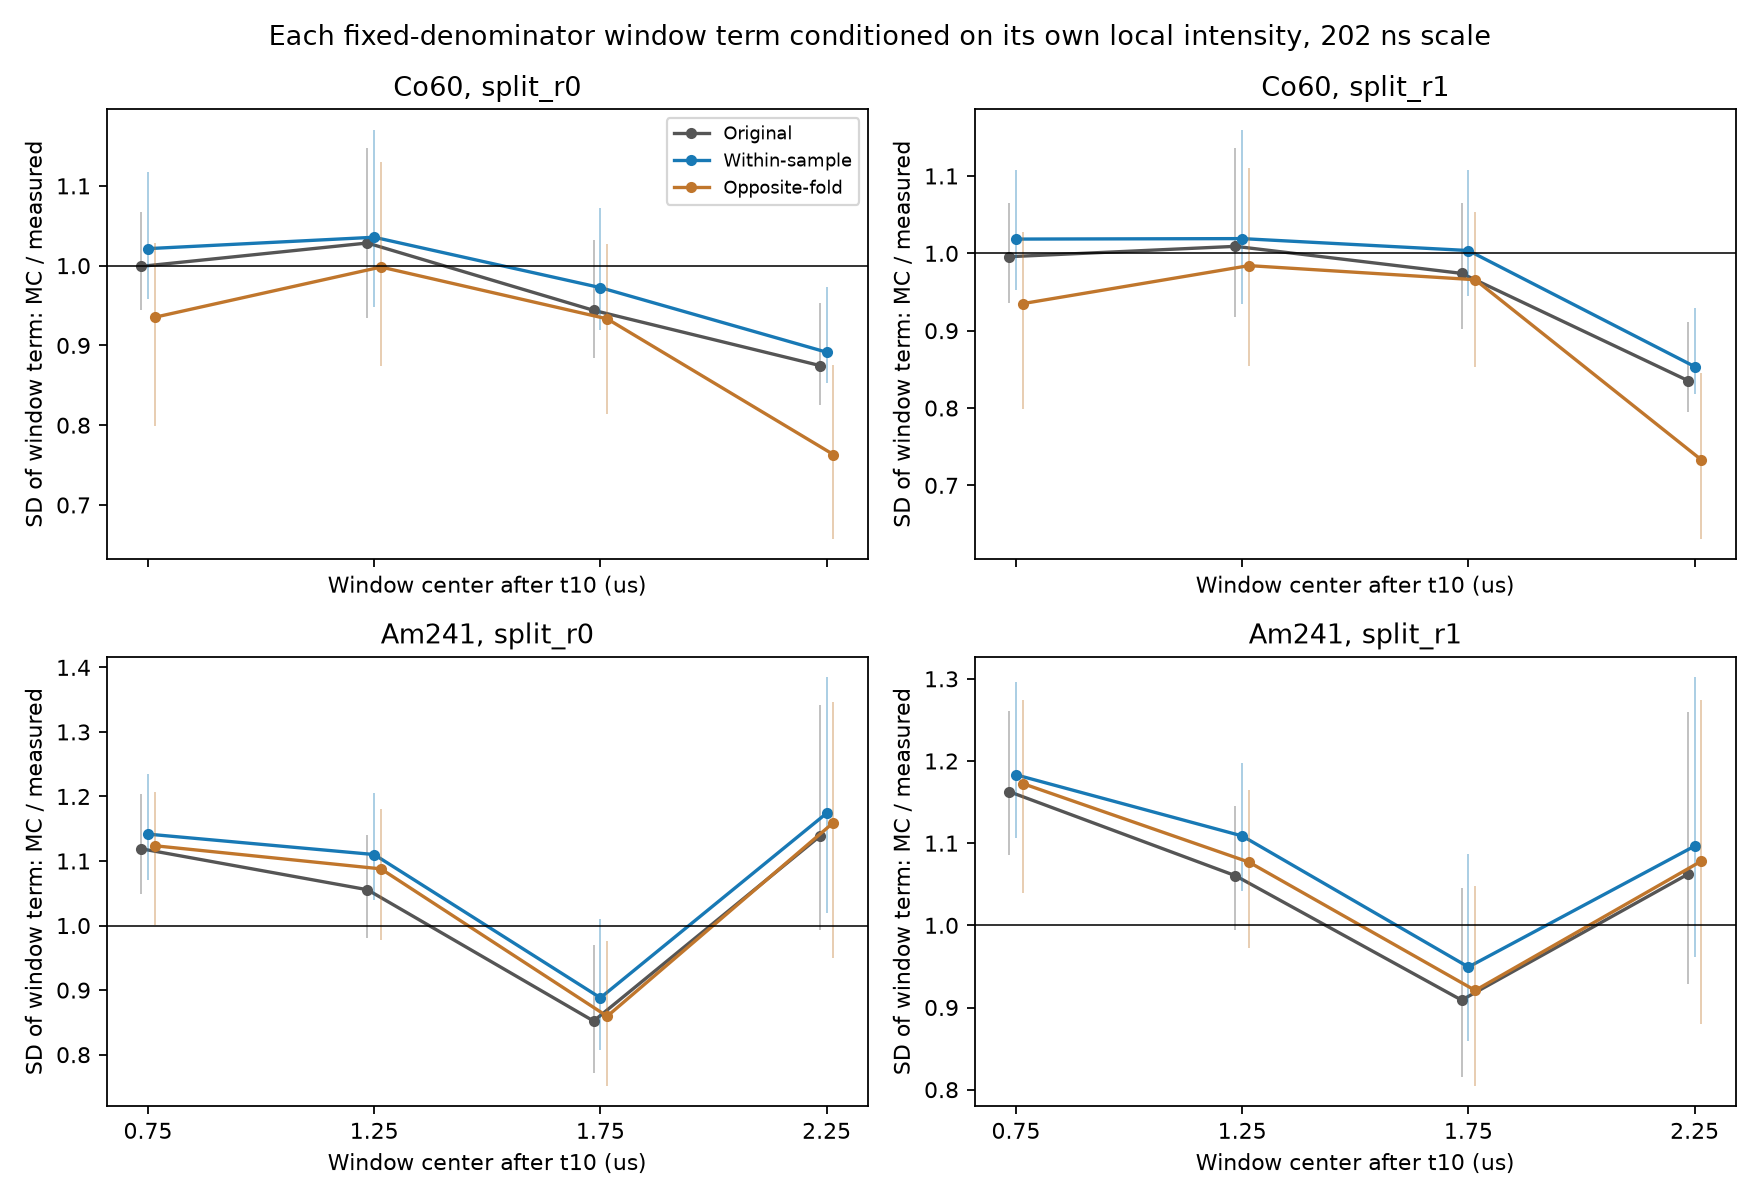

In [3]:
rows=[]
for source,g in a.items():
    for v,r in g['variants'].items():
        for k,predictor in enumerate(p['predictors'][:4]):
            z=r['local'][predictor]['202'];q=z['point']
            rows.append([source,v,f'{500+500*k}–{1000+500*k}',fmt(q['original_SD_ratio']),fmt(q['residual_SD_ratio']),fmt(q['crossfit_residual_SD_ratio']),ci(z['CI95']['crossfit_residual_SD_ratio'])])
display(Markdown(table(['源','读出','窗口/ns','原窗口项SD比','同样本残差比','对折残差比','有效组分位范围'],rows)))
display(Image(filename=str(OUT/'figures/intensity_local_residuals.png')))

## 3. 对折检查与斜率的边界

为了检查同样本拟合的自动变窄，每个Q箱中用另一原始折拟合截距和斜率，预测本折，再把两折残差按原完整Q箱的半箱权重合并，最后在Q箱内中心化。**折间残差均值差仍计入协方差。** MC和实测分别拟合；这里没有把一个样本的斜率作为另一个样本的校正。

对折结果会包含斜率估计噪声，因此残差可能变宽。尤其Co60，不能把对折SD比更接近1说成模拟获得改善。所有实验样本已经探索过，此检查不是新盲验证。

下图斜率是每Q箱内窗口项对无量纲强度的斜率，再对Q箱等权平均。Am241实测与MC的斜率存在差别，但扣除各自线性关系后过宽仍在。全部每Q箱拟合、两折斜率和截距保存于`analysis.json`的`cells`字段；斜率差不能单独确定新的噪声包络参数。


|源|窗口/ns|实测斜率|有效组分位范围|r0斜率|有效组分位范围|r1斜率|有效组分位范围|
|---|---|---|---|---|---|---|---|
|Co60|500–1000|0.09611|[0.0565, 0.1257] (512/512)|0.07556|[0.05012, 0.1032] (512/512)|0.06895|[0.04175, 0.09601] (512/512)|
|Co60|1000–1500|0.06856|[0.02602, 0.1027] (512/512)|0.06581|[0.04897, 0.08315] (512/512)|0.05681|[0.03634, 0.07833] (512/512)|
|Co60|1500–2000|0.1009|[0.07367, 0.1301] (512/512)|0.05241|[0.03564, 0.06985] (512/512)|0.05024|[0.03513, 0.06543] (512/512)|
|Co60|2000–2500|0.08285|[0.06302, 0.1271] (512/512)|0.06018|[0.04376, 0.07558] (512/512)|0.04933|[0.03585, 0.0627] (512/512)|
|Am241|500–1000|0.2266|[0.135, 0.3408] (512/512)|0.1156|[0.05593, 0.1781] (512/512)|0.1385|[0.08536, 0.2005] (512/512)|
|Am241|1000–1500|0.3074|[0.2209, 0.4026] (512/512)|0.07246|[0.0181, 0.1235] (512/512)|0.1261|[0.07479, 0.1791] (512/512)|
|Am241|1500–2000|0.2878|[0.2002, 0.3746] (512/512)|0.06051|[0.01412, 0.1019] (512/512)|0.03114|[-0.01829, 0.07407] (512/512)|
|Am241|2000–2500|0.1803|[0.1152, 0.2622] (512/512)|0.07675|[0.03407, 0.1183] (512/512)|0.07173|[0.03116, 0.1122] (512/512)|

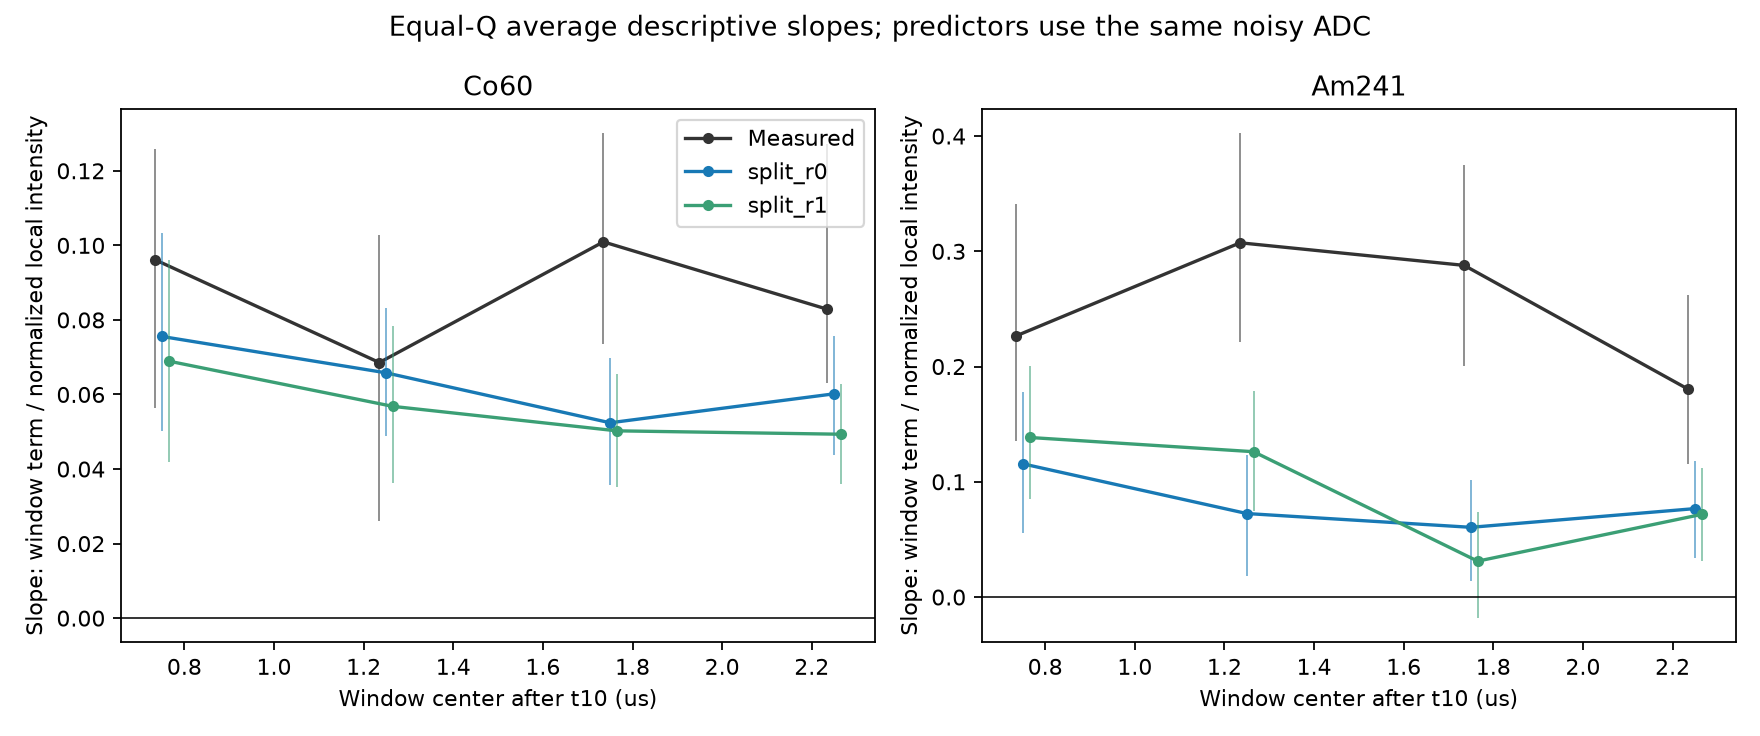

In [4]:
rows=[]
for source,g in a.items():
    for k,predictor in enumerate(p['predictors'][:4]):
        r0=g['variants']['split_r0']['local'][predictor]['202'];r1=g['variants']['split_r1']['local'][predictor]['202']
        rows.append([source,f'{500+500*k}–{1000+500*k}',fmt(r0['point']['data_slope']),ci(r0['CI95']['data_slope']),fmt(r0['point']['MC_slope']),ci(r0['CI95']['MC_slope']),fmt(r1['point']['MC_slope']),ci(r1['CI95']['MC_slope'])])
display(Markdown(table(['源','窗口/ns','实测斜率','有效组分位范围','r0斜率','有效组分位范围','r1斜率','有效组分位范围'],rows)))
display(Image(filename=str(OUT/'figures/intensity_local_slopes.png')))

## 4. 保留不可估计的重采样，不改变比较样本

完全沿用原512组实验事件块和MC母事件的配对计数。**每组都重新估计本轮新增的描述性回归**；已有物理拟合、平均响应、参考、切选和噪声实现保持固定。原始统计的全部512组结果仍须复现上一轮。

原完整Q箱至少需要5个按重采样次数计的事件，并且每个正目标质量的半箱都必须有支持。线性拟合还要求预测量方差大于1e-14；对折检查对每个训练折应用相同事件数与支持规则。任何Q箱不满足条件，则整组相应估计量记为不可估计，不丢弃Q箱、窗口或更改阈值。

原统计与同样本分解均为512/512组有效。Co60实测对折仅399/512组有效，Am241为509/512；MC两条流均512/512。**图表中的对折范围是有效组的2.5%–97.5%分位，不是完整bootstrap的95%置信区间。** Co的缺失比例约22%，限制了对折结果的说服力。所有尺度、窗口共享事件，范围未作多重比较校正，也未覆盖系统误差。

另报告每个Q箱内MC落在实测加权5%–95%强度区间的质量比例。该范围按累计权重插值计算，只描述覆盖情况；没有据此做强度切选或重加权。覆盖良好也不能证明条件分布一致。


|源|样本|原统计有效组|同样本有效组|对折有效组|对折不可估计组|
|---|---|---|---|---|---|
|Co60|data|512|512|399|113|
|Co60|split_r0|512|512|512|0|
|Co60|split_r1|512|512|512|0|
|Am241|data|512|512|509|3|
|Am241|split_r0|512|512|512|0|
|Am241|split_r1|512|512|512|0|

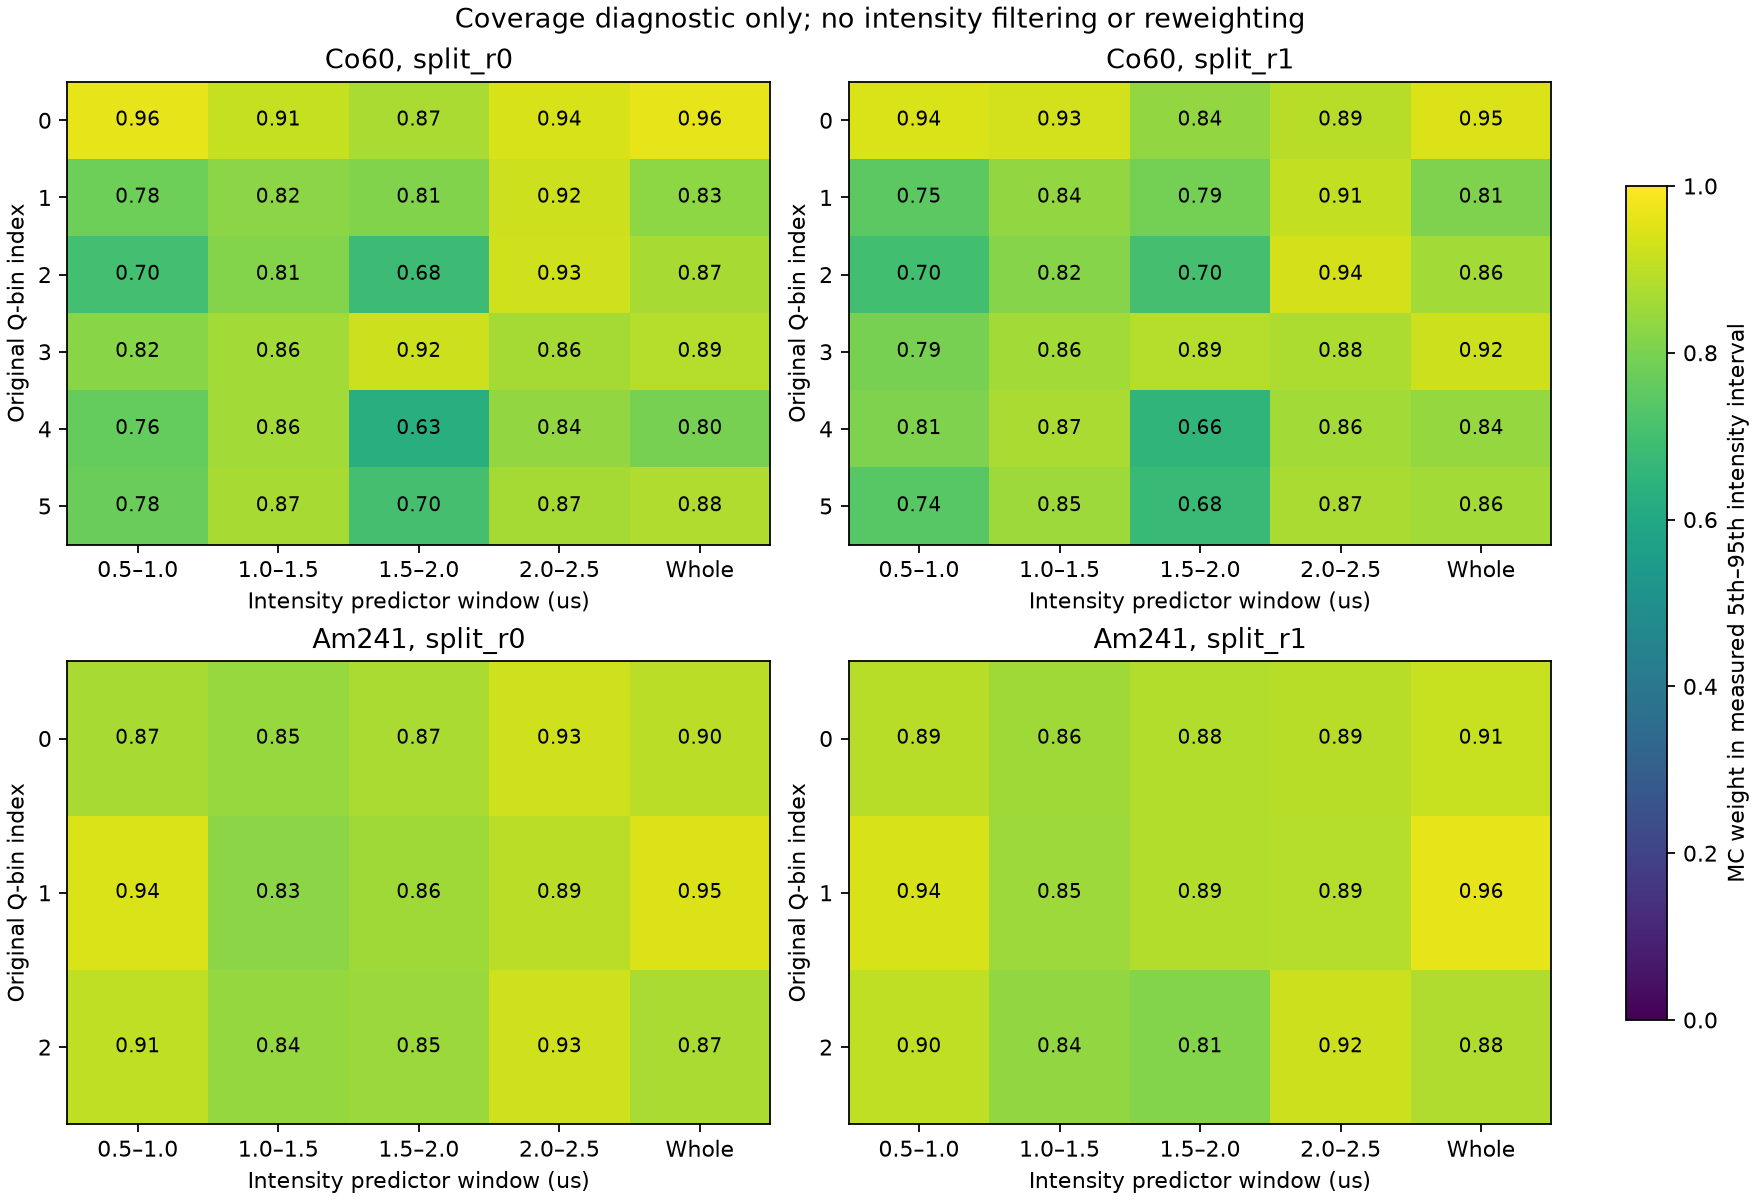

**下一步：**优先检验早期窗口在相近强度下的残余离散及其与其他时段的协方差，提出有界的时间相关方差起伏模型。原生候选须同时保持局部均值、平均ADC、三尺度F与PID协方差；不要用改变平均强度或事后回归残差替代ADC匹配。

边界：新回归在每个有效重采样中重新估计；已有物理拟合、参考、切选和噪声实现仍固定。

边界：Co60有113/512组实测对折重采样因支持不足而不可估计；对折区间只是有效组的分位范围，不能作为完整bootstrap的95%置信区间。Am241也有3组不可估计。

边界：强度与波动来自同一噪声ADC；回归可能包含内生相关、脉冲曲率和源混合，剩余量不是独立物理噪声。

边界：每个数据/MC样本分别拟合；残差变窄不代表存在可用于实验的校正，也不是PID性能改善。

边界：所有窗口、尺度及两条MC读出共享事件；没有新盲样本、实验粒子真值或多重比较校正。

In [5]:
rows=[]
for source,g in a.items():
    for v,n in g['valid_draws'].items():
        rows.append([source,v,n['original'],n['linear'],n['crossfit'],512-n['crossfit']])
display(Markdown(table(['源','样本','原统计有效组','同样本有效组','对折有效组','对折不可估计组'],rows)))
display(Image(filename=str(OUT/'figures/intensity_range_overlap.png')))
display(Markdown('**下一步：**'+d['next_work_zh']))
for text in d['limitations_zh']:display(Markdown('边界：'+text))

## 5. 复现和封存

流程为`analyze_intensity_condition.py` → `report_intensity_condition.py` → 本笔记生成器 → `verify_intensity_condition.py`及`--archive`。分析程序在结果计算前保存方案、输入与源码哈希；`global_table.csv`含60行整体结果，`local_table.csv`含48行窗口结果，全部尺度与预测量均保留。数据来自上一轮已验证的实际ADC分解数组，没有产生新波形。

初次运行的闭合检查发现：新增对折支持要求使部分重采样无效，原实现把这种无效标记也传播给本应保持有效的原统计。该次尚未写出统计结果。修正后分别记录原统计、同样本拟合、对折拟合的有效性，保持原512组统计完整；新回归仍按原规则标记不可估计。未修改阈值、拟合公式、计数或候选。旧方案及三份源码保存在`pre_export_fix_protocol.json`和`pre_export_fix_source/`，修改原因与新旧哈希见`export_fix_record.json`；实际恢复命令使用`--resume-export-fix`。

独立核验使用显式重复事件、带权最小二乘与直接残差协方差，检查点估计及第0/127/511组重采样；同时核对全部512组原统计闭合、所有区间、协方差半正定性、输入哈希、表格行数和已执行笔记。`verification.json`给出实际检查数，`record.json`保存输出哈希和源码快照。五幅图均进行可视检查。

默认参数、正式PID、原ADC和共享文献库均未修改。前一轮时间分段研究已经commit和push，本轮强度条件诊断为随后新增的本地工作。
